# CA3 Random Forest

### Imports

In [200]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

### Settings

In [201]:
test_runs = 50
importance_cutoff = 0.1

# Test parameters set 1
# run_parameters = [
#     {"n_estimators": 100, "max_features": "log2", "max_depth": None},
#     {"n_estimators": 100, "max_features": "sqrt", "max_depth": None},
#     {"n_estimators": 100, "max_features": None, "max_depth": None},
#     {"n_estimators": 100, "max_features": "log2", "max_depth": 3},
#     {"n_estimators": 100, "max_features": "log2", "max_depth": 6},
#     {"n_estimators": 100, "max_features": "log2", "max_depth": 8},
#     {"n_estimators": 100, "max_features": "log2", "max_depth": None},
# ]

# Test parameters set 2
# run_parameters = [
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 1.0, "max_leaf_nodes": 2},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 3, "max_leaf_nodes": 6},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 1.0, "max_leaf_nodes": None},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 3, "max_leaf_nodes": None},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "max_leaf_nodes": None},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "max_leaf_nodes": 2},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "max_leaf_nodes": 4},
#     {"n_estimators": 100, "max_depth": None, "min_samples_split": 2, "max_leaf_nodes": 6},
# ]

# Test parameters set 3
# run_parameters = [
#     {"n_estimators": 50},
#     {"n_estimators": 100},
#     {"n_estimators": 200},
#     {"n_estimators": 300},
#     {"n_estimators": 500},
# ]


# Test parameters set 4
run_parameters = [
    {"n_estimators": 300,
     "max_features": "sqrt",
     "max_depth": None,
     "min_samples_split": 3,
     "max_leaf_nodes": None,
    }]

### Reading data

In [202]:
df_wine = pd.read_csv(r"train.csv")
df_wine_test = pd.read_csv(r"test.csv")

### Data exploration and visualisation

In [203]:
# Check for nan values in columns
df_wine.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [204]:
# Check whether a column contains a negative value or not
(df_wine < 0).any()

fixed acidity           False
volatile acidity        False
citric acid             False
residual sugar          False
chlorides               False
free sulfur dioxide     False
total sulfur dioxide    False
density                 False
pH                      False
sulphates               False
alcohol                 False
quality                 False
Id                      False
dtype: bool

In [205]:
df_wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         835 non-null    float64
 1   volatile acidity      835 non-null    float64
 2   citric acid           835 non-null    float64
 3   residual sugar        835 non-null    float64
 4   chlorides             835 non-null    float64
 5   free sulfur dioxide   835 non-null    float64
 6   total sulfur dioxide  835 non-null    float64
 7   density               835 non-null    float64
 8   pH                    835 non-null    float64
 9   sulphates             835 non-null    float64
 10  alcohol               835 non-null    float64
 11  quality               835 non-null    int64  
 12  Id                    835 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 84.9 KB


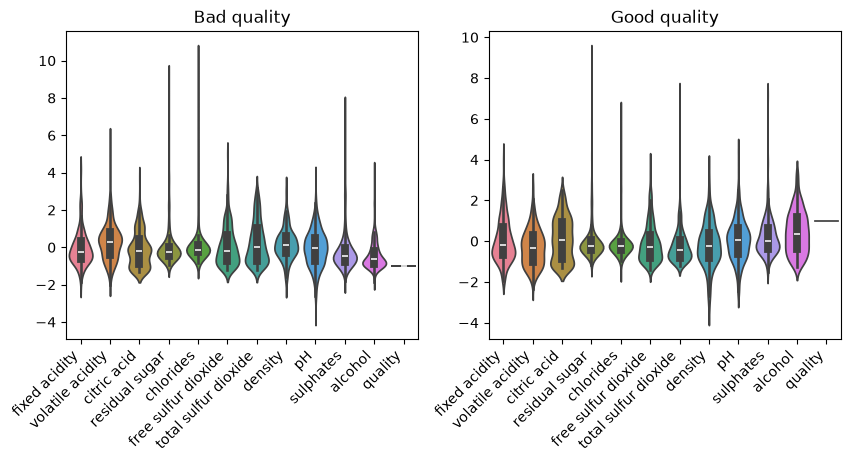

In [206]:
df_plot = df_wine.drop(columns=["Id"])

column_names = df_plot.columns

for name in column_names:
    df_plot[name] = (df_plot[name]-df_plot[name].mean())/df_plot[name].std()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

plt.setp(ax[0].get_xticklabels(), rotation=45, ha='right')
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')

ax[0].set_title("Bad quality")
ax[1].set_title("Good quality")

sns.violinplot(data=df_plot.loc[df_wine["quality"]==0], ax=ax[0])
sns.violinplot(data=df_plot.loc[df_wine["quality"]==1], ax=ax[1])

plt.show()

### Attribute comparison <br>
Higher values indicate a feature is more important for classification of quality wines



<Axes: title={'center': 'Feature importance comparison'}>

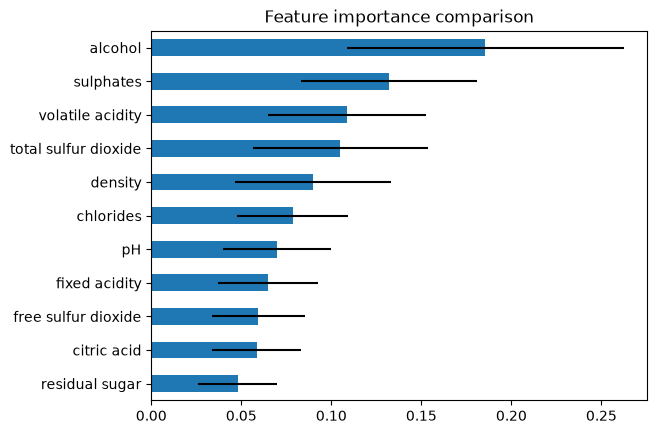

In [207]:
X_train, X_val, y_train, y_val = train_test_split(df_wine.iloc[:, :-2], df_wine.iloc[:, -2], test_size=0.3, random_state=1, stratify=df_wine.iloc[:, -2])

# Train logistic regression model
clf = RandomForestClassifier().fit(X_train, np.array(y_train).flatten())
classifier_score = clf.score(X_val, np.array(y_val).flatten())


feature_select_std = np.std([tree.feature_importances_ for tree in clf.estimators_], axis=0)
stacked_feature_std = np.column_stack((clf.feature_importances_, feature_select_std))

importance_features = pd.DataFrame(stacked_feature_std, columns=["Importance", "std"])
importance_features.index = X_train.columns

importance_features = importance_features.sort_values(by="Importance", ascending=True)

importance_features["Importance"].plot.barh(xerr=importance_features["std"], title="Feature importance comparison")





### Data cleaning

In [208]:
df_train = df_wine.drop(columns=importance_features.loc[importance_features["Importance"] < importance_cutoff].index)
df_train = df_train.drop(columns="Id")

df_test = df_wine_test.drop(columns=importance_features.loc[importance_features["Importance"] < importance_cutoff].index)
df_test = df_test.drop(columns="Id")

df_train


,volatile acidity,total sulfur dioxide,sulphates,alcohol,quality
0,0.610,29.0,1.56,9.1,0
1,1.035,54.0,0.49,9.9,0
2,0.290,53.0,1.01,12.4,1
3,0.340,63.0,0.79,14.0,1
4,0.645,23.0,0.74,11.1,0
...,...,...,...,...,...
830,0.320,9.0,0.55,12.3,1
831,0.510,54.0,0.93,10.7,1
832,0.725,11.0,0.39,10.9,0
833,0.835,19.0,0.47,9.6,0


### Data preprocessing and visualisation

In [209]:
# Separate into class labels and attributes
column_names = df_train.columns
df_y = df_train.drop(columns=[x for x in column_names if x != "quality"])
df_train = df_train.drop(columns="quality")


### Random forest trials

In [210]:
rng = np.random.default_rng()

print(f"Intializing random forest test run. Current amount of test runs {test_runs}")

columns_results = ["max", "min", "mean", "std"]
for param_name in run_parameters[0].keys():
    columns_results.append(param_name)

df_run_results = pd.DataFrame(columns=columns_results)
df_run_results.index.name = "run"
# Based on settings run test LogReg models and parameters
random_states = rng.choice(1000, size=test_runs, replace=False)
run_summary = np.zeros(test_runs)

for params in run_parameters:
    for idx, rand_num in enumerate(random_states):
        X_train, X_val, y_train, y_val = train_test_split(df_train, df_y, test_size=0.3, random_state=rand_num, stratify=df_y)

        # Train random forest model
        clf = RandomForestClassifier(**params).fit(X_train, np.array(y_train).flatten())
        classifier_score = clf.score(X_val, np.array(y_val).flatten())
        run_summary[idx] = classifier_score

    
    row_df = [
        run_summary.max(),
        run_summary.min(),
        run_summary.mean(), 
        run_summary.std(), 
         
        ]
    
    for element in params.values():
        row_df.append(element)

    df_run_results.loc[len(df_run_results)] = row_df

# Finds
"""
Repeat runs showed that these are the best results for the first set of parameters in settings:
    max_features: sqrt (Marginally better)
    max_depth: None (Risk of overfitting)

Repeat runs showed that these are the best results for the second set of parameters in settings:
    min_samples_split: 3
    max_leaf_nodes: None

Repeat runs showed that these are the best results for the second set of parameters in settings:
    n_estimators: 300


These parameters combined produced the worst result so far on kaggle
"""
df_run_results


Intializing random forest test run. Current amount of test runs 50


,max,min,mean,std,n_estimators,max_features,max_depth,min_samples_split,max_leaf_nodes
run,,,,,,,,,
0,0.840637,0.709163,0.775777,0.023892,300,sqrt,None,3,None


### Kaggle export data

In [211]:
# Predict using scaled test set
submission = pd.DataFrame(clf.predict(df_test), columns=["TARGET"])
submission.index.name = "Id"
submission.to_csv("Kaggle_randomforest_result.csv")